# Fitting 2D images

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/05_2d_images.ipynb)
[![PyPI version](https://img.shields.io/pypi/v/htfa.svg)](https://pypi.org/project/htfa/)

A 2D image is a special case of the model: the pixels are the locations, with `(row, column)` coordinates, and each image is one sample. `htfa.fit` and `htfa.load` read PNG, JPEG, TIFF and other common image formats (through Pillow, the `images` extra) and numpy arrays of shape `(H, W)`.

This tutorial writes small image files to a temporary folder (30 x 30 pixels), loads them in each way (`channels`, `spacing`, multi-page TIFF, `stack=True`), and fits TFA to a single image. The gallery example *TFA on a real 2D image* applies the same fit to a photograph.

This is an illustration of the coordinate-based model outside fMRI: spatial factors describe pixel patterns, and their weights reconstruct image samples or color channels. The generated blobs provide simple known spatial features; the photograph illustrates the extra detail that a small factor basis can leave unexplained.

In [2]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q htfa

In [3]:
import tempfile
import time
import warnings
from pathlib import Path

import numpy as np

import htfa
from htfa.synthetic import match_factors

plt = htfa.require("matplotlib.pyplot")
Image = htfa.require("PIL.Image")

H = W = 30
rows, cols = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")
pix = np.stack([rows.ravel(), cols.ravel()], axis=1).astype(float)


def blobs(centers, widths, amps):
    """Image made of Gaussian blobs, scaled to 1-255 uint8 (no zero pixels)."""
    d2 = ((pix[:, None, :] - np.asarray(centers, float)[None]) ** 2).sum(axis=2)
    img = np.exp(-d2 / np.asarray(widths, float)) @ np.asarray(amps, float)
    img = img.reshape(H, W)
    return np.round(1 + 254 * (img - img.min()) / (img.max() - img.min())).astype(
        np.uint8
    )


centers = [(8, 9), (20, 10), (14, 22)]
widths = [30.0, 30.0, 30.0]
rng = np.random.default_rng(0)
gray = blobs(centers, widths, [1.0, 1.0, 1.0])
rgb = np.stack(
    [blobs(centers, widths, a) for a in ([1, 0, 0], [0, 1, 0], [0, 0, 1])], axis=-1
)  # one blob per color channel

tmp = tempfile.TemporaryDirectory()
root = Path(tmp.name)
Image.fromarray(gray).save(root / "gray.png")
Image.fromarray(rgb).save(root / "color.png")
Image.fromarray(rgb).save(root / "color.jpg", quality=95)
pages = [Image.fromarray(np.roll(gray, 3 * i, axis=1)) for i in range(5)]
pages[0].save(root / "pages.tif", save_all=True, append_images=pages[1:])
print(sorted(p.name for p in root.iterdir()))

['color.jpg', 'color.png', 'gray.png', 'pages.tif']


## 1. Loading one image

A grayscale PNG is one subject with one sample. The coordinates are `(row, column)` pixel indices times `spacing` (default 1). `Subject.to_image` maps a `(V,)` or `(V, T)` array back to the image grid.

In [4]:
(s,) = htfa.load(str(root / "gray.png"))
print(
    "data (V, T):",
    s.data.shape,
    "| coords:",
    s.coords.shape,
    "| image_shape:",
    s.image_shape,
)
print("first coordinates:", s.coords[:2].tolist(), "| last:", s.coords[-1].tolist())
back = s.to_image(s.data[:, 0])
print("to_image round trip equals the file's pixels:", np.array_equal(back, gray))

(s2,) = htfa.load(str(root / "gray.png"), spacing=2.5)
print("with spacing=2.5, last coordinate:", s2.coords[-1].tolist())

data (V, T): (900, 1) | coords: (900, 2) | image_shape: (30, 30)
first coordinates: [[0.0, 0.0], [0.0, 1.0]] | last: [29.0, 29.0]
to_image round trip equals the file's pixels: True
with spacing=2.5, last coordinate: [72.5, 72.5]


The default mask keeps every finite pixel of a 2D image: black pixels are data here. (For NIfTI volumes the default also drops locations that are zero at every sample, as out-of-brain screening.) To drop black pixels, pass an explicit mask:

In [5]:
with_black = gray.copy()
with_black[:3, :3] = 0
Image.fromarray(with_black).save(root / "black.png")
(keep,) = htfa.load(str(root / "black.png"))
(drop,) = htfa.load(str(root / "black.png"), mask=with_black > 0)
print("default mask, image with 9 black pixels: V =", keep.data.shape[0], "of", H * W)
print("mask=with_black > 0                     : V =", drop.data.shape[0])

default mask, image with 9 black pixels: V = 900 of 900
mask=with_black > 0                     : V = 891


## 2. Color images: `channels='gray'` and `'separate'`

For a color image `channels='gray'` (default) converts to grayscale with the ITU-R 601 weights (0.299 R + 0.587 G + 0.114 B), giving one sample. `channels='separate'` keeps the color channels, giving one sample per channel (3 for RGB). The image below has a different blob in each channel.

In [6]:
(g,) = htfa.load(str(root / "color.png"))
(sep,) = htfa.load(str(root / "color.png"), channels="separate")
print("gray    :", g.data.shape)
print("separate:", sep.data.shape)
luma = rgb.reshape(-1, 3) @ np.array([0.299, 0.587, 0.114])
print("max |gray - 601 luma of the pixels|:", np.abs(g.data[:, 0] - luma).max())
print(
    "separate channel 0 equals the red channel:",
    np.array_equal(sep.data[:, 0], rgb[..., 0].ravel()),
)

(jpg,) = htfa.load(str(root / "color.jpg"), channels="separate")
print("JPEG (lossy) vs PNG, max channel difference:", np.abs(jpg.data - sep.data).max())

gray    : (900, 1)
separate: (900, 3)
max |gray - 601 luma of the pixels|: 0.0
separate channel 0 equals the red channel: True
JPEG (lossy) vs PNG, max channel difference: 17.0


`'gray'` reproduces the ITU-R 601 luma of the decoded pixels, and `'separate'` returns the three channels as columns. The printed JPEG–PNG difference measures loss from JPEG compression.

## 3. Several images: TIFF pages and `stack=True`

The pages of a multi-page TIFF are the samples of one subject. For a folder, each image file is its own subject by default; with `stack=True` all images of the same size are the samples of one subject.

In [7]:
(tif,) = htfa.load(str(root / "pages.tif"))
print("multi-page TIFF:", tif.data.shape, "(V, pages)")

folder = root / "frames"
folder.mkdir()
for i in range(4):
    Image.fromarray(np.roll(gray, 4 * i, axis=0)).save(folder / f"frame-{i}.png")
print(
    "folder, default :",
    len(htfa.load(str(folder))),
    "subjects,",
    htfa.load(str(folder))[0].data.shape,
)
print(
    "folder, stack   :",
    len(htfa.load(str(folder), stack=True)),
    "subject, ",
    htfa.load(str(folder), stack=True)[0].data.shape,
)

multi-page TIFF: (900, 5) (V, pages)
folder, default : 4 subjects, (900, 1)
folder, stack   : 1 subject,  (900, 4)


## 4. Fitting a single image: `standardize=True` against the default

One image is one sample, so `standardize='auto'` leaves it unchanged (it z-scores over samples, and there is only one). TFA has no intercept and its ridge penalty on the weights is `var(X)`, which for raw intensities is in squared intensity units. `standardize=True` z-scores the pixels across the image when `T == 1`.

The two fits below use the same image, K, and seed. The first uses the default; the second `standardize=True`. The printed centers and widths describe the fitted factors. The upper width bound is `upper_ratio * 2 max(std(R))^2`.

In [8]:
R = s.coords
ub = 1.8 * 2 * R.std(axis=0).max() ** 2
print(f"upper width bound: {ub:.1f}")
true_c = np.array(centers, float)

fits = {}
for std in ["auto", True]:
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = htfa.fit(str(root / "gray.png"), K=3, standardize=std, random_state=0)
    fits[std] = res
    sd = res.subjects[0].data[:, 0]
    zs = (sd - sd.mean()) / sd.std()
    rr = np.corrcoef(zs, res.reconstruct(0)[:, 0])[0, 1]
    print(f"   correlation of the reconstruction with the z-scored image: {rr:.3f}")
    m = res.model
    print(
        f"standardize={std!r:5} ({time.perf_counter() - t0:.1f} s): "
        f"stop={m.converged_reason_}, init={m.init_}"
    )
    print("   centers:", np.round(m.centers_, 1).tolist())
    print("   widths :", np.round(m.widths_, 1).tolist())
    perm = match_factors(true_c, m.centers_)
    print(
        "   distance of each estimated center to the blob center:",
        np.round(np.linalg.norm(m.centers_[perm] - true_c, axis=1), 1).tolist(),
    )

upper width bound: 269.7
   correlation of the reconstruction with the z-scored image: 0.767
standardize='auto' (0.1 s): stop=threshold, init=power
   centers: [[14.1, 13.4], [14.1, 13.4], [14.1, 13.4]]
   widths : [269.7, 269.7, 269.7]
   distance of each estimated center to the blob center: [7.5, 6.8, 8.6]
   correlation of the reconstruction with the z-scored image: 0.936
standardize=True  (0.0 s): stop=threshold, init=power
   centers: [[14.0, 21.7], [19.4, 10.2], [8.5, 9.2]]
   widths : [14.5, 16.1, 15.4]
   distance of each estimated center to the blob center: [0.5, 0.6, 0.3]


The raw-intensity fit can place several factors at a similar location with broad widths. Its ridge penalty scales with `var(X)`, and the model has no intercept to absorb a positive image background. Standardizing the image changes both its offset and the penalty scale. Compare the centers, widths, and reconstruction correlations for the two fits. This tutorial uses `standardize=True` for single images.

## 5. The standardized fit

The reconstruction of the `standardize=True` fit is in the standardized space, so the image is shown z-scored too. The crosses are the estimated factor centers and the circles the blob centers used to make the image.

correlation of the reconstruction with the z-scored image: 0.936
fitted width / drawing width (30): [0.48, 0.54, 0.51]


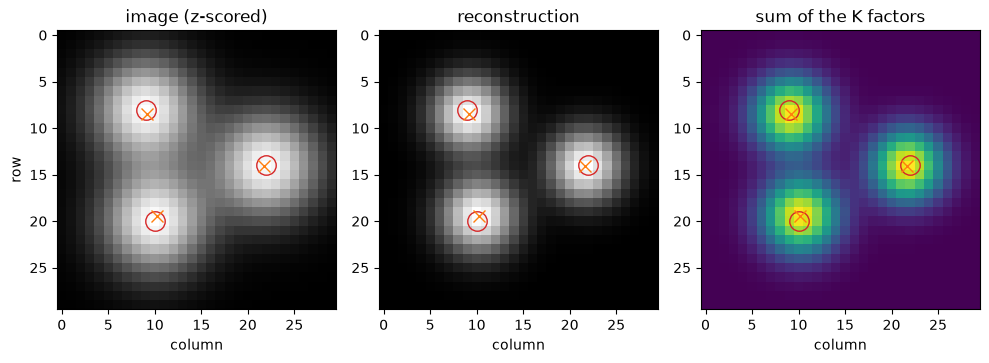

In [9]:
res = fits[True]
sub = res.subjects[0]
z = (sub.data[:, 0] - sub.data[:, 0].mean()) / sub.data[:, 0].std()
r = np.corrcoef(z, res.reconstruct(0)[:, 0])[0, 1]
print(f"correlation of the reconstruction with the z-scored image: {r:.3f}")
print(
    "fitted width / drawing width (30):", np.round(res.model.widths_ / 30, 2).tolist()
)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
axes[0].imshow(sub.to_image(z), cmap="gray")
axes[0].set_title("image (z-scored)")
axes[1].imshow(res.to_image(0)[..., 0], cmap="gray")
axes[1].set_title("reconstruction")
axes[2].imshow(res.to_image(0, what="factors").sum(axis=-1), cmap="viridis")
axes[2].set_title("sum of the K factors")
for ax in axes:
    ax.plot(true_c[:, 1], true_c[:, 0], "o", mfc="none", mec="tab:red", ms=14)
    ax.plot(
        res.model.centers_[:, 1], res.model.centers_[:, 0], "x", c="tab:orange", ms=8
    )
    ax.set_xlabel("column")
axes[0].set_ylabel("row")
fig.tight_layout()
plt.show()

The printed ratios compare fitted width parameters with the value 30 in the generating blobs. Overlap, min–max scaling, and z-scoring change the spatial profile of the input, so fitted widths need not recover the drawing width.

## 6. Separate channels, fitted

With `channels='separate'` the image has three samples, and `standardize='auto'` z-scores each pixel over the three channels. The weights then have one column per channel.

In [10]:
t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    res3 = htfa.fit(str(root / "color.png"), K=3, channels="separate", random_state=0)
print(
    f"fit time: {time.perf_counter() - t0:.1f} s | stop: {res3.model.converged_reason_}"
)
print("weights shape (K, channels):", res3.weights[0].shape)
print("weights:\n", np.round(res3.weights[0], 2))
print("centers:", np.round(res3.model.centers_, 1).tolist())

fit time: 0.0 s | stop: threshold
weights shape (K, channels): (3, 3)
weights:
 [[-1.05  2.23 -1.18]
 [-1.   -1.09  2.1 ]
 [ 2.22 -1.09 -1.13]]
centers: [[21.9, 9.3], [13.9, 23.8], [6.5, 8.5]]


The weights have one column per channel. Compare each factor's center with the channel-specific blob locations, then inspect which channel has its largest weight. Per-pixel standardization centers each pixel across channels, which also centers the fitted factor time courses up to numerical error.

## 7. More factors, more detail

The blob images above contain three Gaussian blobs, so K = 3 suffices. A photograph has detail at many scales. The cell below fits the photograph from the gallery example *TFA on a real 2D image* (`china.jpg`, bundled with scikit-learn, no download), block-averaged by 16 to 26 x 40 pixels, with K = 2, 5, 10, 20 and 40, and reports the R² of each reconstruction against the z-scored image. To keep the run short, each fit uses one start (`init='power'`) instead of the default three candidates; the time of a fit grows quickly with K (K = 40 takes the most time here).

In [11]:
from sklearn.datasets import load_sample_image

photo = load_sample_image("china.jpg")  # (427, 640, 3) uint8
b = 16
h, w = photo.shape[0] // b, photo.shape[1] // b
small = photo[: h * b, : w * b].reshape(h, b, w, b, 3).mean(axis=(1, 3))
china = small @ np.array([0.299, 0.587, 0.114])  # ITU-R 601 luma
print("image:", photo.shape, "->", china.shape)

Ks = [2, 5, 10, 20, 40]
recons, r2s = {}, {}
for k in Ks:
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        rk = htfa.fit(china, K=k, standardize=True, init="power", random_state=0)
    x = rk.subjects[0].data[:, 0]
    zk = (x - x.mean()) / x.std()
    resid = zk - rk.reconstruct(0)[:, 0]
    r2s[k] = 1 - (resid**2).sum() / (zk**2).sum()
    recons[k] = rk.to_image(0)[..., 0]
    print(
        f"K={k:3d} ({time.perf_counter() - t0:4.1f} s): R^2 = {r2s[k]:.3f}, "
        f"median width = {np.median(rk.model.widths_):6.1f} pixels^2"
    )
z_china = rk.subjects[0].to_image(zk)

image: (427, 640, 3) -> (26, 40)
K=  2 ( 0.0 s): R^2 = 0.534, median width =  103.0 pixels^2
K=  5 ( 0.0 s): R^2 = 0.824, median width =   70.6 pixels^2
K= 10 ( 0.0 s): R^2 = 0.902, median width =   53.0 pixels^2
K= 20 ( 0.1 s): R^2 = 0.932, median width =   13.2 pixels^2


K= 40 ( 0.3 s): R^2 = 0.950, median width =    6.0 pixels^2


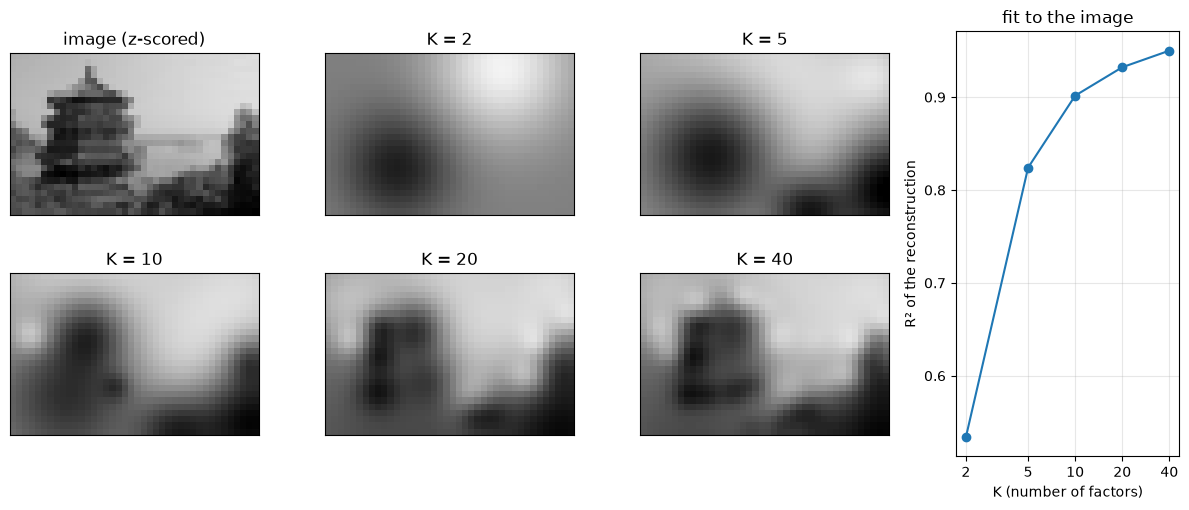

In [12]:
fig = plt.figure(figsize=(12, 5.2))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.9])
panels = [("image (z-scored)", z_china)]
panels += [(f"K = {k}", recons[k]) for k in Ks]
lim = np.abs(z_china).max()
for i, (title, im) in enumerate(panels):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    ax.imshow(im, cmap="gray", vmin=-lim, vmax=lim)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
ax = fig.add_subplot(gs[:, 3])
ax.plot(Ks, [r2s[k] for k in Ks], "o-", c="tab:blue")
ax.set_xscale("log")
ax.set_xticks(Ks, [str(k) for k in Ks])
ax.minorticks_off()
ax.set_xlabel("K (number of factors)")
ax.set_ylabel("R² of the reconstruction")
ax.set_title("fit to the image")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Each factor is a Gaussian bump with a center and width; its weighted contribution is summed with the other factors to reconstruct the image. Compare the reconstruction panels, median widths, and R² as K grows. Narrower factors can represent smaller image features, while local optimization can affect the score. These R² values describe the fitted pixels, so they do not establish generalization to other images.

In [13]:
tmp.cleanup()